In [ ]:
from google.colab import drive
drive.mount('/content/drive/')
%cd /content/drive/My Drive/Colab Notebooks/BigO project

Mounted at /content/drive/
[Errno 2] No such file or directory: '/content/drive/My Drive/Colab Notebooks/BigO project'
/content


In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib as mpl

inspections = pd.read_csv("data/raw/Food_Inspections_20261012.csv")
licenses = pd.read_csv("data/raw/Business_Licenses_-_Current_Active_20261012.csv")
cca = pd.read_csv("data/raw/CommunityDataSnapshots_Historical_455993172616713182.csv")

/tmp/ipykernel_9635/682619899.py:8: DtypeWarning: Columns (9: ZIP CODE) have mixed types. Specify dtype option on import or set low_memory=False.
  licenses = pd.read_csv("data/raw/Business_Licenses_-_Current_Active_20261012.csv")


In [2]:
inspections = inspections[[
    "Inspection ID", "DBA Name", "License #", "Facility Type",
    "Address", "Inspection Date", "Results", "Violations"
]].copy()

licenses = licenses[[
    "LICENSE NUMBER", "COMMUNITY AREA"
]].copy()

cca = cca[[
    "GEOID", "GEOG", "TOT_POP", "MEDINC"
]].copy()

inspections["Inspection Date"] = pd.to_datetime(
    inspections["Inspection Date"])

inspections = inspections[
    (inspections["Facility Type"] == "Restaurant")
    & inspections["Violations"].notna()
    & inspections["Violations"].ne("")
]

inspections = inspections.drop_duplicates()

inspections["License #"] = pd.to_numeric(inspections["License #"])
licenses["LICENSE NUMBER"] = pd.to_numeric(licenses["LICENSE NUMBER"])
licenses["COMMUNITY AREA"] = pd.to_numeric(licenses["COMMUNITY AREA"])
cca["GEOID"] = pd.to_numeric(cca["GEOID"])


licenses = licenses.dropna().drop_duplicates()
licenses = licenses[licenses["LICENSE NUMBER"] > 0]


licenses = licenses[
    ~licenses["LICENSE NUMBER"].duplicated(keep=False)
]

cca = cca.dropna(subset=["GEOID"])

combined = inspections.merge(
    licenses,
    left_on="License #",
    right_on="LICENSE NUMBER",
    how="inner",
    validate="many_to_one"
)

combined = combined.merge(
    cca,
    left_on="COMMUNITY AREA",
    right_on="GEOID",
    how="inner",
    validate="many_to_one"
)

failed = combined[combined["Results"] == "Pass"]

summary = (
    failed.groupby("GEOG")
    .agg(
        Fail_Count=("Inspection ID", "count"),
        Median_Income=("MEDINC", "first")
    )
    .reset_index()
)

print("Total inspections:", len(combined))
print("Matched to CMAP:", combined["GEOG"].notna().sum())
display(combined.head())


Total inspections: 76764
Matched to CMAP: 76764


,Inspection ID,DBA Name,License #,Facility Type,Address,Inspection Date,Results,Violations,LICENSE NUMBER,COMMUNITY AREA,GEOID,GEOG,TOT_POP,MEDINC
0,2644038,SIMPLY SOUPS SALADS & SANDWICHES,2222369.0,Restaurant,635 E 47TH ST,2026-10-09,Pass,"55. PHYSICAL FACILITIES INSTALLED, MAINTAINED ...",2222369,38.0,38,Grand Boulevard,25181.0,50075.107296
1,2644032,AGLAIA COFFEE AND TEA COMPANY,2749668.0,Restaurant,925 W CHICAGO AVE,2026-10-09,Fail,2. CITY OF CHICAGO FOOD SERVICE SANITATION CER...,2749668,24.0,24,West Town,88164.0,141208.345621
2,2644015,SIP & SAVOR COFFEE HOUSE,3002330.0,Restaurant,528 E 43RD ST,2026-10-09,Fail,10. ADEQUATE HANDWASHING SINKS PROPERLY SUPPLI...,3002330,38.0,38,Grand Boulevard,25181.0,50075.107296
3,2643969,SHARKS ON DIVISION CORPORATION,3046001.0,Restaurant,5751 W DIVISION ST,2026-10-08,Fail,"1. PERSON IN CHARGE PRESENT, DEMONSTRATES KNOW...",3046001,25.0,25,Austin,97452.0,47532.573290
4,2644004,ADORO FUSION KITCHEN + BAR,2083875.0,Restaurant,2509 W NORTH AVE,2026-10-08,Fail,16. FOOD-CONTACT SURFACES: CLEANED & SANITIZED...,2083875,24.0,24,West Town,88164.0,141208.345621


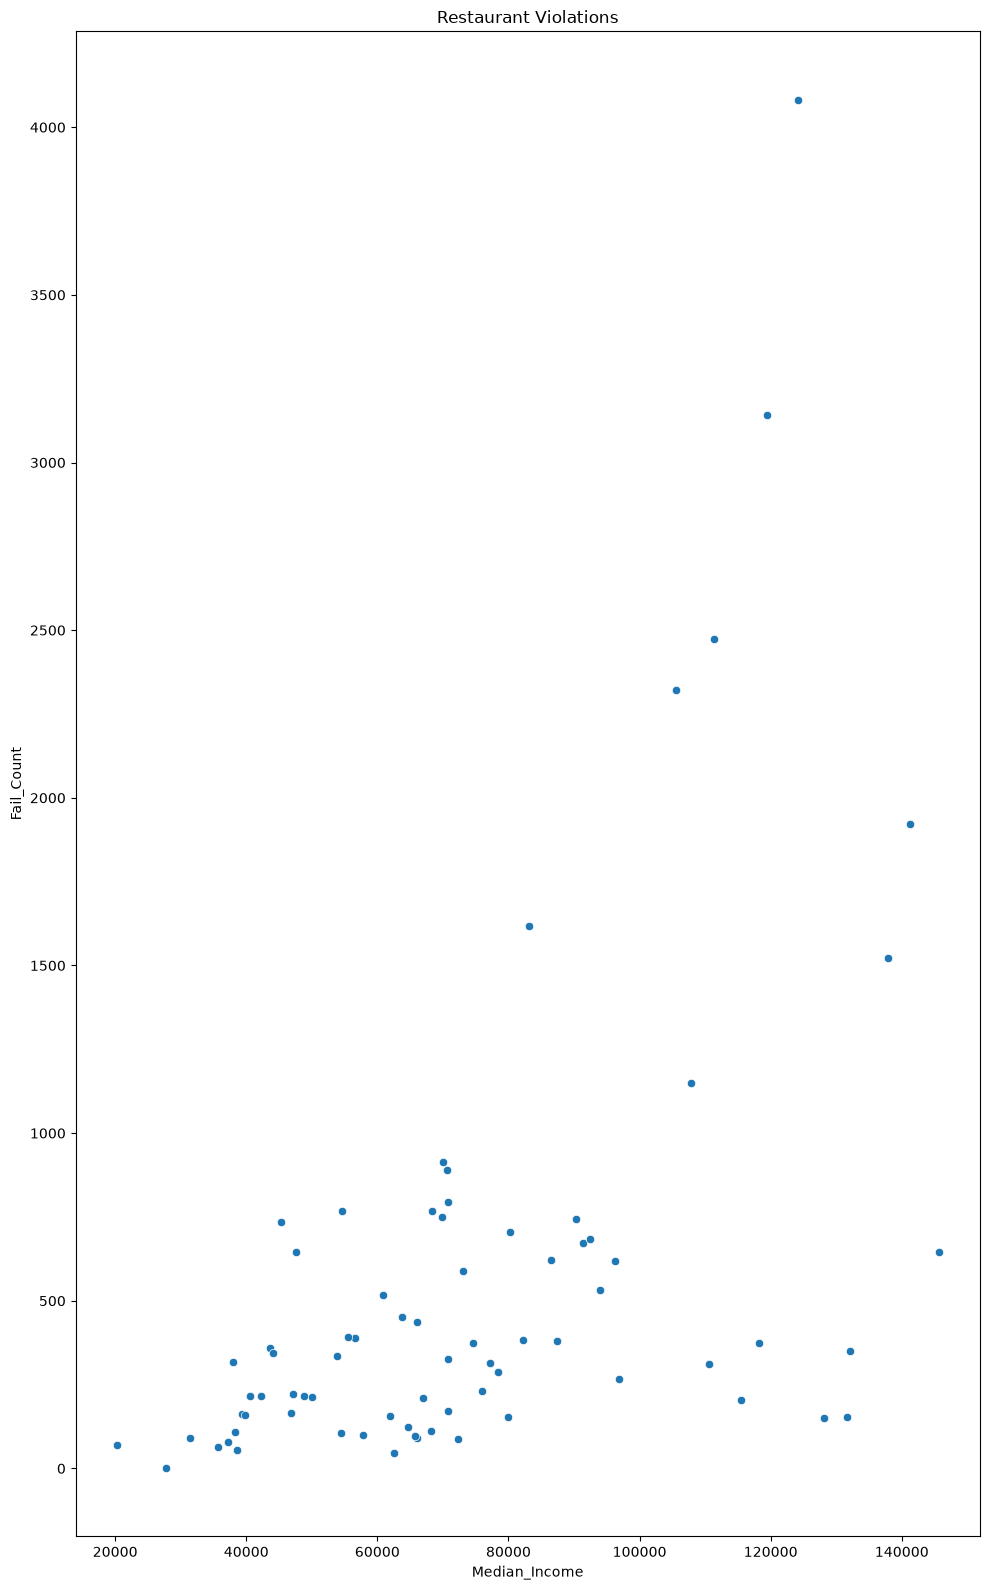

In [3]:
plt.figure(figsize=(10, 16))

sns.scatterplot(
    data=summary,
    x="Median_Income",
    y="Fail_Count"
)

plt.title("Restaurant Violations")
plt.tight_layout()
plt.show()